In [1]:
%pip install celltypist "scanpy==1.11.5" "anndata==0.11.4" "zarr<3"

In [2]:
from pathlib import Path
from importlib.metadata import version

import scanpy as sc
import celltypist
from celltypist import models

import os

# Locate the shared project folder from the notebook working directory.
_start = Path.cwd().resolve()
_override = os.environ.get("GUILLIAMS_PROJECT_DIR")
if _override:
    _project_root = Path(_override).expanduser().resolve()
else:
    _project_root = next(
        (p for p in (_start, *_start.parents)
         if (p / "guilliams_metadata").is_dir()),
        None,
    )
    if _project_root is None:
        raise FileNotFoundError(
            "Keep guilliams_metadata beside the repository, "
            "or set GUILLIAMS_PROJECT_DIR."
        )
PROJECT_DIR = Path(os.path.relpath(_project_root, _start))
INPUT_DIR = PROJECT_DIR / "guilliams_qc" / "human" / "doublet_review"

sample_id = "GSM5764363"
input_path = INPUT_DIR / f"{sample_id}_doublet_scored.h5ad"

adata = sc.read_h5ad(input_path)

required_columns = {"doublet_score", "predicted_doublet_auto"}
missing = required_columns - set(adata.obs.columns)

if missing:
    raise ValueError(f"Missing doublet metadata: {missing}")

if "gene_name" not in adata.var:
    raise ValueError("Gene symbols are missing.")

print("CellTypist version:", version("celltypist"))
print("Scanpy version:", version("scanpy"))
print("Sample:", sample_id)
print("Shape (cells, genes):", adata.shape)
print("First 5 gene IDs:", adata.var_names[:5].tolist())
print("First 5 gene symbols:", adata.var["gene_name"].head().tolist())
print("Doublet review status:", adata.uns["doublet_review_status"])

%pip check

In [3]:
import numpy as np
import pandas as pd
import anndata as ad
from scipy import sparse

# Validate gene symbols before combining duplicate names.
symbols = adata.var["gene_name"]

if symbols.isna().any():
    raise ValueError("Missing gene symbols.")

symbols = symbols.astype(str)
if symbols.str.strip().eq("").any():
    raise ValueError("Empty gene symbols.")

codes, unique_symbols = pd.factorize(symbols, sort=False)

# Map original gene columns to unique gene symbols.
mapping = sparse.csr_matrix(
    (
        np.ones(adata.n_vars, dtype=np.int64),
        (np.arange(adata.n_vars), codes),
    ),
    shape=(adata.n_vars, len(unique_symbols)),
)

counts = sparse.csr_matrix(adata.X)
symbol_counts = (counts @ mapping).tocsr()

# Combining duplicate symbols must preserve each cell's total counts.
np.testing.assert_array_equal(
    np.asarray(counts.sum(axis=1)).ravel(),
    np.asarray(symbol_counts.sum(axis=1)).ravel(),
)

gene_mapping = pd.DataFrame({
    "gene_id": adata.var_names.to_numpy(),
    "gene_symbol": symbols.to_numpy(),
})

source_ids = (
    gene_mapping.groupby("gene_symbol", sort=False)["gene_id"]
    .agg(lambda values: ";".join(values))
    .reindex(unique_symbols)
)

annotation_data = ad.AnnData(
    X=symbol_counts,
    obs=adata.obs.copy(),
    var=pd.DataFrame(
        {"source_gene_ids": source_ids.to_numpy()},
        index=pd.Index(unique_symbols, name="gene_symbol"),
    ),
)

print("Original gene rows:", adata.n_vars)
print("Unique gene symbols:", annotation_data.n_vars)
print("Duplicate rows combined:", adata.n_vars - annotation_data.n_vars)
print("Cells retained:", annotation_data.n_obs)
print("Per-cell count preservation: PASS")

Original gene rows: 32738
Unique gene symbols: 32643
Duplicate rows combined: 95
Cells retained: 9598
Per-cell count preservation: PASS


In [4]:
from celltypist import models

MODEL_NAME = "Healthy_Human_Liver.pkl"

# Download only the model needed for this analysis.
models.download_models(
    model=MODEL_NAME,
    force_update=False,
)
liver_model = models.Model.load(model=MODEL_NAME)

model_genes = set(liver_model.features)
input_genes = set(annotation_data.var_names)
shared_genes = model_genes & input_genes

if not shared_genes:
    raise ValueError("No shared genes between the data and the model.")

print("Model:", MODEL_NAME)
print("Model description:")
print(liver_model.description)

print("\nModel genes:", len(model_genes))
print("Shared genes:", len(shared_genes))
print(
    "Model gene coverage (%):",
    round(100 * len(shared_genes) / len(model_genes), 2),
)

print("\nAvailable cell types:")
for cell_type in liver_model.cell_types:
    print(cell_type)

📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in ~/.celltypist/data/models
💾 Total models to download: 1
💾 Downloading model [1/1]: Healthy_Human_Liver.pkl


Model: Healthy_Human_Liver.pkl
Model description:
{'date': '2023-09-14 12:48:54.179790', 'details': 'cell types from scRNA-seq and snRNA-seq of the adult human liver', 'url': 'https://celltypist.cog.sanger.ac.uk/models/Human_Liver_Guilliams/v1/Healthy_Human_Liver.pkl', 'source': 'https://doi.org/10.1016/j.cell.2021.12.018', 'version': 'v1', 'number_celltypes': 17}

Model genes: 2691
Shared genes: 2688
Model gene coverage (%): 99.89

Available cell types:
B cells
Basophils
Cholangiocytes
Circulating NK/NKT
Endothelial cells
Fibroblasts
Hepatocytes
Macrophages
Mig.cDCs
Mono+mono derived cells
Neutrophils
Plasma cells
Resident NK
T cells
cDC1s
cDC2s
pDCs


In [5]:
import scanpy as sc
import celltypist
import numpy as np

# Normalize a separate copy, preserving the raw count objects.
annotation_input = annotation_data.copy()
annotation_input.X = annotation_input.X.astype(np.float32)

sc.pp.normalize_total(annotation_input, target_sum=10_000)
sc.pp.log1p(annotation_input)

# Verify normalization without converting the matrix to dense format.
recovered_totals = np.asarray(
    annotation_input.X.expm1().sum(axis=1)
).ravel()

np.testing.assert_allclose(
    recovered_totals,
    10_000,
    rtol=1e-4,
)

# Obtain individual predictions before cluster-based majority voting.
predictions = celltypist.annotate(
    annotation_input,
    model=liver_model,
    majority_voting=False,
)

labels = predictions.predicted_labels["predicted_labels"].reindex(
    annotation_input.obs_names
)
scores = predictions.probability_matrix.max(axis=1).reindex(
    annotation_input.obs_names
)

if labels.isna().any() or scores.isna().any():
    raise ValueError("Missing predictions after cell ID alignment.")

annotation_input.obs["celltypist_label"] = labels
annotation_input.obs["celltypist_score"] = scores

print("Cells annotated:", annotation_input.n_obs)
print("\nPredicted cell types:")
print(annotation_input.obs["celltypist_label"].value_counts())

print("\nPrediction score summary:")
print(
    annotation_input.obs["celltypist_score"]
    .describe(percentiles=[0.1, 0.5, 0.9])
    .round(3)
)

🔬 Input data has 9598 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


Cells annotated: 9598

Predicted cell types:
celltypist_label
Mono+mono derived cells    6054
Neutrophils                1330
Macrophages                1130
cDC2s                       387
cDC1s                       210
Endothelial cells           180
T cells                     111
B cells                      66
pDCs                         63
Circulating NK/NKT           21
Mig.cDCs                     18
Resident NK                  11
Cholangiocytes                8
Plasma cells                  7
Fibroblasts                   2
Name: count, dtype: int64

Prediction score summary:
count    9598.000
mean        0.904
std         0.166
min         0.011
10%         0.672
50%         0.989
90%         1.000
max         1.000
Name: celltypist_score, dtype: float64


liver-cell-map/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


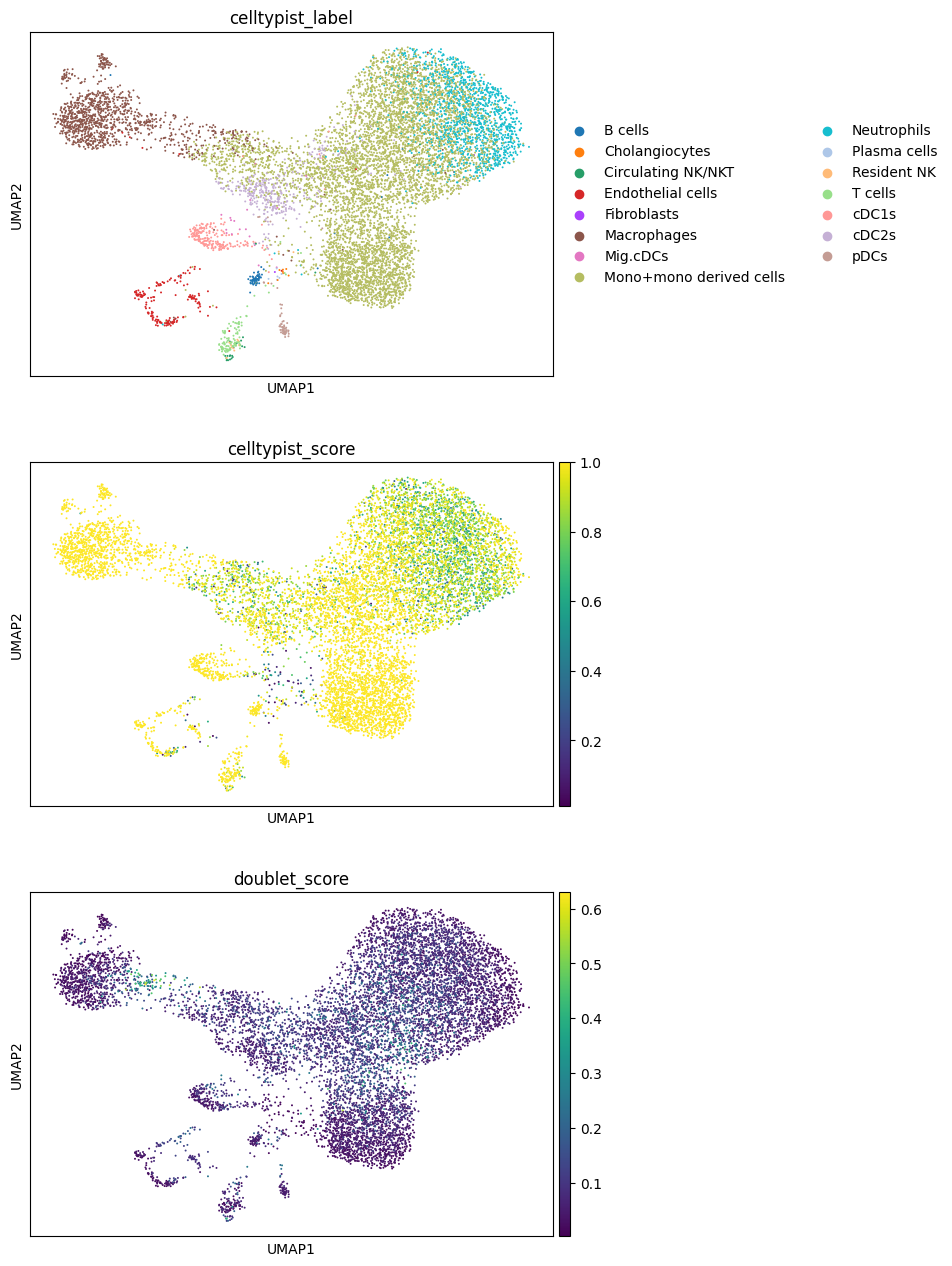

In [6]:
from sklearn.neighbors import KNeighborsTransformer
import matplotlib.pyplot as plt

# Select genes for dimensionality reduction without removing other genes.
sc.pp.highly_variable_genes(
    annotation_input,
    n_top_genes=2000,
    flavor="seurat",
)

sc.tl.pca(
    annotation_input,
    n_comps=30,
    mask_var="highly_variable",
    random_state=0,
)

# Use exact neighbors to avoid the earlier sparse-array compatibility issue.
sc.pp.neighbors(
    annotation_input,
    n_neighbors=15,
    n_pcs=30,
    transformer=KNeighborsTransformer(
        n_neighbors=15,
        mode="distance",
        metric="euclidean",
        algorithm="brute",
    ),
    random_state=0,
)

sc.tl.umap(annotation_input, random_state=0)

sc.pl.umap(
    annotation_input,
    color=[
        "celltypist_label",
        "celltypist_score",
        "doublet_score",
    ],
    ncols=1,
    size=8,
    show=False,
)

plt.show()

In [7]:
# Summarize predictions and QC metrics by provisional cell type.
review_table = (
    annotation_input.obs
    .groupby("celltypist_label", observed=True)
    .agg(
        cells=("celltypist_label", "size"),
        median_annotation_score=("celltypist_score", "median"),
        annotation_score_below_0_5_pct=(
            "celltypist_score",
            lambda values: 100 * (values < 0.5).mean(),
        ),
        median_doublet_score=("doublet_score", "median"),
        doublet_score_p95=(
            "doublet_score",
            lambda values: values.quantile(0.95),
        ),
        median_counts=("total_counts", "median"),
        median_genes=("n_genes_by_counts", "median"),
    )
    .sort_values("cells", ascending=False)
)

display(review_table.round(3))

# Save the exploratory result, including predictions and UMAP.
annotation_dir = PROJECT_DIR / "guilliams_annotation" / "human"
annotation_dir.mkdir(parents=True, exist_ok=True)

annotation_input.uns["processing_stage"] = "exploratory_annotation"
annotation_input.uns["cell_type_annotation_performed"] = True
annotation_input.uns["annotation_model"] = MODEL_NAME
annotation_input.uns["annotation_status"] = "requires_marker_review"
annotation_input.uns["doublet_filtering_performed"] = False
annotation_input.uns["count_scale"] = "log1p normalized to 10000 per cell"

annotation_input.write_h5ad(
    annotation_dir / f"{sample_id}_exploratory_annotation.h5ad",
    compression="gzip",
)
review_table.to_csv(
    annotation_dir / f"{sample_id}_annotation_review.csv"
)

print("Saved exploratory annotation:", sample_id)

,cells,median_annotation_score,annotation_score_below_0_5_pct,median_doublet_score,doublet_score_p95,median_counts,median_genes
celltypist_label,,,,,,,
Mono+mono derived cells,6054,0.987,3.518,0.068,0.193,3601.0,1227.0
Neutrophils,1330,0.852,9.774,0.048,0.125,1940.5,804.0
Macrophages,1130,1.000,0.973,0.040,0.278,3797.5,1289.0
cDC2s,387,0.980,6.718,0.070,0.165,8612.0,2123.0
cDC1s,210,1.000,2.381,0.050,0.189,10509.0,2197.5
Endothelial cells,180,1.000,5.000,0.060,0.193,2594.5,1084.5
T cells,111,1.000,9.009,0.031,0.237,2546.0,972.0
B cells,66,1.000,0.000,0.040,0.181,2847.0,968.0
pDCs,63,1.000,3.175,0.048,0.230,4580.0,1562.0


Saved exploratory annotation: GSM5764363


Missing marker genes: []


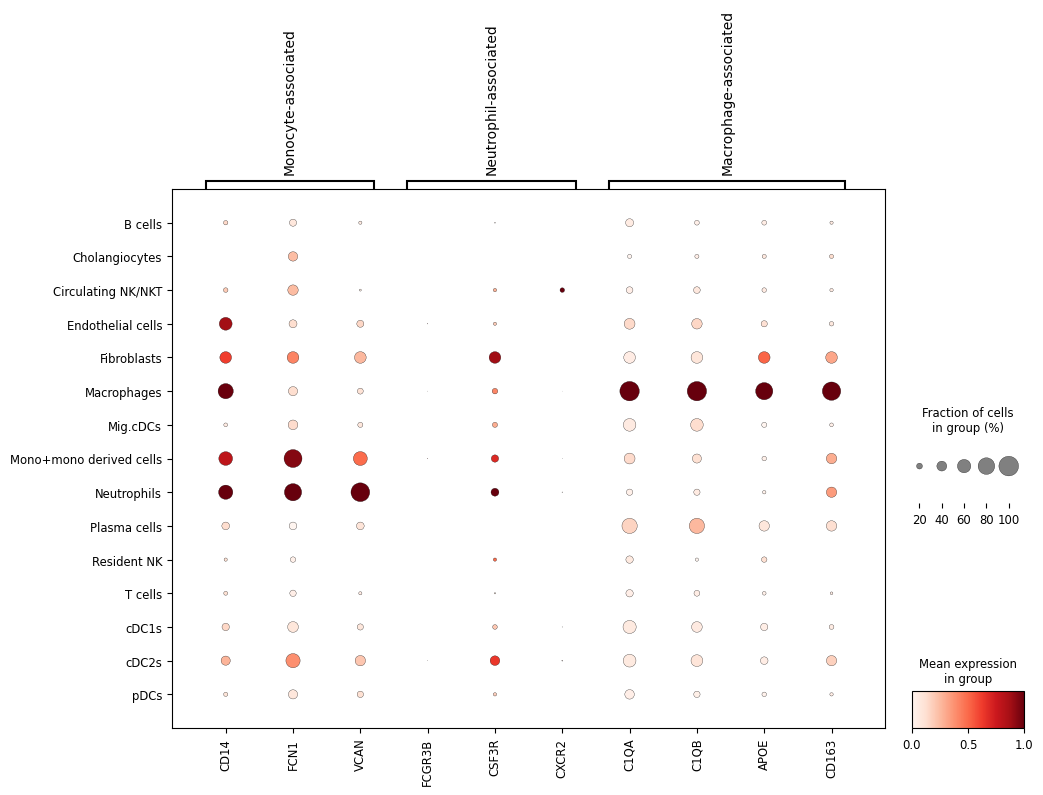

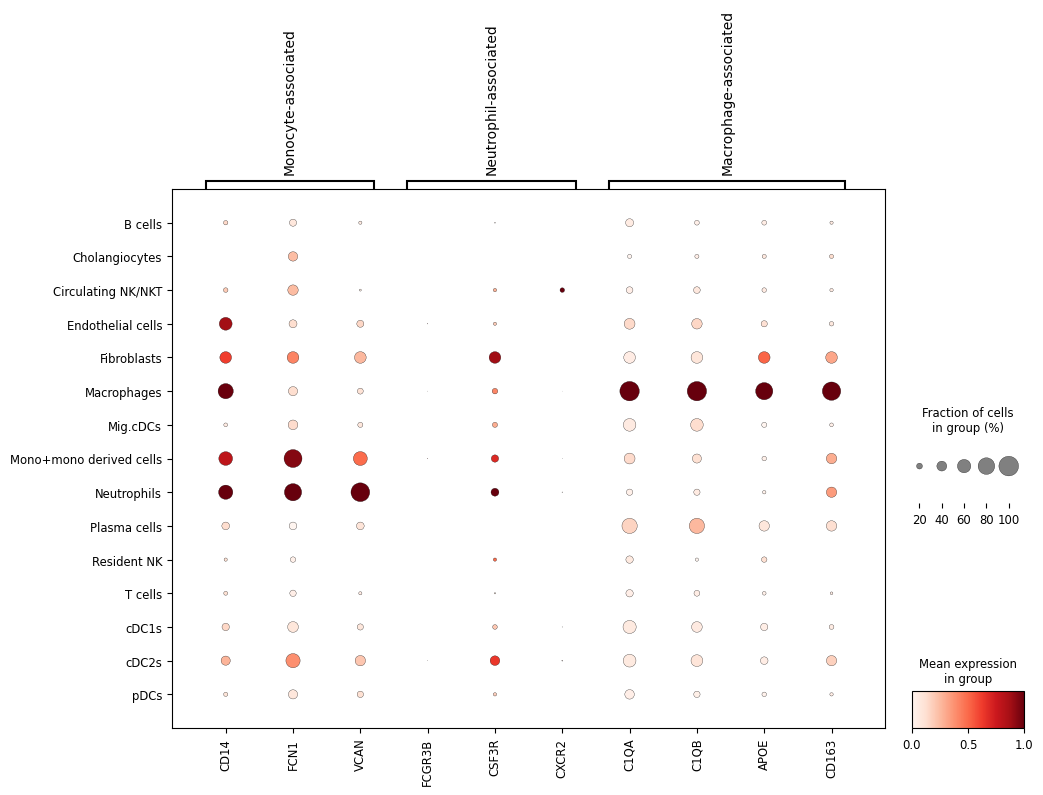

In [8]:
# Inspect marker expression across provisional model labels.
marker_panel = {
    "Monocyte-associated": ["CD14", "FCN1", "VCAN"],
    "Neutrophil-associated": ["FCGR3B", "CSF3R", "CXCR2"],
    "Macrophage-associated": ["C1QA", "C1QB", "APOE", "CD163"],
}

missing_genes = [
    gene
    for genes in marker_panel.values()
    for gene in genes
    if gene not in annotation_input.var_names
]
print("Missing marker genes:", missing_genes)

available_markers = {
    group: [
        gene for gene in genes
        if gene in annotation_input.var_names
    ]
    for group, genes in marker_panel.items()
}
available_markers = {
    group: genes
    for group, genes in available_markers.items()
    if genes
}

if not available_markers:
    raise ValueError("No marker genes are available.")

plot = sc.pl.dotplot(
    annotation_input,
    var_names=available_markers,
    groupby="celltypist_label",
    use_raw=False,
    standard_scale="var",
    dendrogram=False,
    figsize=(11, 7),
    return_fig=True,
)

plot.savefig(
    annotation_dir / f"{sample_id}_myeloid_marker_dotplot.png",
    dpi=180,
    bbox_inches="tight",
)
plot.show()

In [9]:
# Reuse the existing neighbor graph for cluster-based majority voting.
voted_predictions = celltypist.annotate(
    annotation_input,
    model=liver_model,
    majority_voting=True,
)

voted_labels = voted_predictions.predicted_labels.reindex(
    annotation_input.obs_names
)

if voted_labels["majority_voting"].isna().any():
    raise ValueError("Missing majority-voting labels.")

annotation_input.obs["celltypist_label"] = (
    voted_labels["predicted_labels"]
)
annotation_input.obs["celltype_native"] = (
    voted_labels["majority_voting"]
)
annotation_input.obs["celltypist_cluster"] = (
    voted_labels["over_clustering"].astype(str)
)

# Record the probability score for the voted label, when available.
probabilities = voted_predictions.probability_matrix.reindex(
    annotation_input.obs_names
)
voted_names = annotation_input.obs["celltype_native"].astype(str)

annotation_input.obs["celltypist_conf"] = [
    probabilities.iloc[i][label]
    if label in probabilities.columns else np.nan
    for i, label in enumerate(voted_names)
]

# Preserve marker-review concerns for both original and voted labels.
review_labels = {"Neutrophils", "Fibroblasts"}
annotation_input.obs["needs_marker_review"] = (
    annotation_input.obs["celltypist_label"].isin(review_labels)
    | annotation_input.obs["celltype_native"].isin(review_labels)
)

changed = (
    annotation_input.obs["celltypist_label"].astype(str)
    != voted_names
)

print("Cells retained:", annotation_input.n_obs)
print("Labels changed by majority voting:", int(changed.sum()))
print("\nMajority-voting labels:")
print(annotation_input.obs["celltype_native"].value_counts())

print("\nLabel transitions:")
display(pd.crosstab(
    annotation_input.obs["celltypist_label"],
    annotation_input.obs["celltype_native"],
))

🔬 Input data has 9598 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


Cells retained: 9598
Labels changed by majority voting: 1323

Majority-voting labels:
celltype_native
Mono+mono derived cells    6534
Neutrophils                1059
Macrophages                 993
cDC2s                       315
cDC1s                       245
Endothelial cells           195
T cells                     127
B cells                      78
pDCs                         52
Name: count, dtype: int64

Label transitions:


celltype_native,B cells,Endothelial cells,Macrophages,Mono+mono derived cells,Neutrophils,T cells,cDC1s,cDC2s,pDCs
celltypist_label,,,,,,,,,
B cells,59,0,1,6,0,0,0,0,0
Cholangiocytes,0,0,0,5,0,0,3,0,0
Circulating NK/NKT,0,0,0,2,0,18,1,0,0
Endothelial cells,0,176,0,1,1,1,1,0,0
Fibroblasts,0,0,0,0,1,0,1,0,0
Macrophages,1,4,988,135,1,0,1,0,0
Mig.cDCs,1,0,0,2,0,0,14,1,0
Mono+mono derived cells,4,11,4,5682,284,0,7,62,0
Neutrophils,0,3,0,553,772,0,1,1,0


In [10]:
# Save raw counts with provisional annotations and exploratory coordinates.
handoff_dir = PROJECT_DIR / "guilliams_annotation" / "human" / "handoff"
handoff_dir.mkdir(parents=True, exist_ok=True)

if not annotation_data.obs_names.equals(annotation_input.obs_names):
    raise ValueError("Cell IDs are not aligned.")

handoff = annotation_data.copy()

label_columns = [
    "celltypist_label",
    "celltypist_score",
    "celltype_native",
    "celltypist_cluster",
    "celltypist_conf",
    "needs_marker_review",
]

for column in label_columns:
    handoff.obs[column] = annotation_input.obs[column].copy()

handoff.obs["label_changed_by_voting"] = (
    handoff.obs["celltypist_label"].astype(str)
    != handoff.obs["celltype_native"].astype(str)
)
handoff.obsm["X_umap"] = annotation_input.obsm["X_umap"].copy()

handoff.uns["processing_stage"] = "provisional_annotation_handoff"
handoff.uns["count_scale"] = "raw RNA counts summed by gene symbol"
handoff.uns["annotation_model"] = MODEL_NAME
handoff.uns["annotation_status"] = "provisional"
handoff.uns["doublet_detection_performed"] = True
handoff.uns["doublet_filtering_performed"] = False
handoff.uns["doublet_review_status"] = "threshold_requires_review"
handoff.uns["source_file"] = str(input_path.relative_to(PROJECT_DIR))
handoff.uns["review_notes"] = (
    "Neutrophil predictions have limited support from the inspected "
    "marker panel. Majority voting absorbs some small predicted classes. "
    "Both individual and majority-voting labels are retained."
)
handoff.uns["confidence_definition"] = (
    "celltypist_score: maximum individual model probability score; "
    "celltypist_conf: model probability score for the majority-voted label. "
    "Neither is a calibrated probability of annotation correctness."
)

output_path = handoff_dir / f"{sample_id}_provisional_annotation.h5ad"
handoff.write_h5ad(output_path, compression="gzip")

check = ad.read_h5ad(output_path)
assert check.obs_names.equals(handoff.obs_names)
assert check.var_names.equals(handoff.var_names)
assert (check.X != handoff.X).nnz == 0

print("Saved shape:", check.shape)
print("Read-back verification: PASS")
print("Saved:", output_path)

del check, handoff

... storing 'celltypist_cluster' as categorical


Saved shape: (9598, 32643)
Read-back verification: PASS
Saved: guilliams_annotation/human/handoff/GSM5764363_provisional_annotation.h5ad


In [11]:
import gc
import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import celltypist
from scipy import sparse
from sklearn.neighbors import KNeighborsTransformer

handoff_dir = PROJECT_DIR / "guilliams_annotation" / "human" / "handoff"
handoff_dir.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    PROJECT_DIR / "guilliams_qc" / "human" / "basic_qc"
    / "export_summary.csv"
)

def annotate_library(source_path):
    source = sc.read_h5ad(source_path)
    symbols = source.var["gene_name"]

    if symbols.isna().any() or symbols.astype(str).str.strip().eq("").any():
        raise ValueError("Missing or empty gene symbols.")

    symbols = symbols.astype(str)
    codes, unique_symbols = pd.factorize(symbols, sort=False)

    mapping = sparse.csr_matrix(
        (
            np.ones(source.n_vars, dtype=np.int64),
            (np.arange(source.n_vars), codes),
        ),
        shape=(source.n_vars, len(unique_symbols)),
    )
    counts = (sparse.csr_matrix(source.X) @ mapping).tocsr()

    np.testing.assert_array_equal(
        np.asarray(source.X.sum(axis=1)).ravel(),
        np.asarray(counts.sum(axis=1)).ravel(),
    )

    gene_map = pd.DataFrame({
        "gene_id": source.var_names.to_numpy(),
        "gene_symbol": symbols.to_numpy(),
    })
    source_ids = (
        gene_map.groupby("gene_symbol", sort=False)["gene_id"]
        .agg(lambda values: ";".join(values))
        .reindex(unique_symbols)
    )

    result = ad.AnnData(
        X=counts,
        obs=source.obs.copy(),
        var=pd.DataFrame(
            {"source_gene_ids": source_ids.to_numpy()},
            index=pd.Index(unique_symbols, name="gene_symbol"),
        ),
    )
    result.uns = source.uns.copy()
    del source

    work = result.copy()
    work.X = work.X.astype(np.float32)
    sc.pp.normalize_total(work, target_sum=10_000)
    sc.pp.log1p(work)

    sc.pp.highly_variable_genes(
        work, n_top_genes=2000, flavor="seurat"
    )
    sc.tl.pca(
        work,
        n_comps=30,
        mask_var="highly_variable",
        random_state=0,
    )
    sc.pp.neighbors(
        work,
        n_neighbors=15,
        n_pcs=30,
        transformer=KNeighborsTransformer(
            n_neighbors=15,
            mode="distance",
            metric="euclidean",
            algorithm="brute",
        ),
        random_state=0,
    )

    pred = celltypist.annotate(
        work, model=liver_model, majority_voting=True
    )
    labels = pred.predicted_labels.reindex(result.obs_names)
    probabilities = pred.probability_matrix.reindex(result.obs_names)

    if labels.isna().any().any():
        raise ValueError("Missing annotation labels.")

    result.obs["celltypist_label"] = labels["predicted_labels"]
    result.obs["celltype_native"] = labels["majority_voting"]
    result.obs["celltypist_cluster"] = (
        labels["over_clustering"].astype(str)
    )
    result.obs["celltypist_score"] = probabilities.max(axis=1)

    voted = result.obs["celltype_native"].astype(str)
    result.obs["celltypist_conf"] = [
        probabilities.iloc[i][label]
        if label in probabilities.columns else np.nan
        for i, label in enumerate(voted)
    ]
    result.obs["label_changed_by_voting"] = (
        result.obs["celltypist_label"].astype(str) != voted
    )

    # These libraries have not undergone individual marker review.
    result.obs["needs_marker_review"] = True
    result.uns["processing_stage"] = "provisional_annotation_handoff"
    result.uns["count_scale"] = "raw RNA counts summed by gene symbol"
    result.uns["annotation_model"] = MODEL_NAME
    result.uns["annotation_status"] = "provisional"
    result.uns["doublet_filtering_performed"] = False
    result.uns["source_file"] = str(source_path.relative_to(PROJECT_DIR))
    result.uns["review_notes"] = (
        "Individual marker review has not been performed. "
        "Doublet thresholds remain unresolved. "
        "Individual and majority-voting predictions are retained. "
        "The annotation model originates from the same study."
    )
    result.uns["confidence_definition"] = (
        "celltypist_score: maximum individual model probability score; "
        "celltypist_conf: probability score for the majority-voted label. "
        "These are not calibrated probabilities of correctness."
    )
    return result


summaries = []
failures = []
celltype_tables = []

for index, record in enumerate(manifest.to_dict("records"), start=1):
    accession = record["sample"]
    output_path = handoff_dir / f"{accession}_provisional_annotation.h5ad"
    result = None
    check = None

    try:
        if accession == "GSM5764363" and output_path.exists():
            result = sc.read_h5ad(output_path)
        else:
            source_path = INPUT_DIR / f"{accession}_doublet_scored.h5ad"
            result = annotate_library(source_path)
            result.write_h5ad(output_path, compression="gzip")

        if result.n_obs != int(record["cells_saved"]):
            raise ValueError("Unexpected change in cell count.")

        check = sc.read_h5ad(output_path)
        assert check.obs_names.equals(result.obs_names)
        assert check.var_names.equals(result.var_names)
        assert (check.X != result.X).nnz == 0
        pd.testing.assert_frame_equal(
            check.obs[["celltypist_label", "celltype_native"]],
            result.obs[["celltypist_label", "celltype_native"]],
        )

        summaries.append({
            "sample": accession,
            "donor": record["donor"],
            "condition": record["condition"],
            "cells": result.n_obs,
            "gene_symbols": result.n_vars,
            "labels_changed": int(
                result.obs["label_changed_by_voting"].sum()
            ),
            "median_individual_score": float(
                result.obs["celltypist_score"].median()
            ),
            "status": "provisional",
            "file": str(output_path.relative_to(PROJECT_DIR)),
        })

        table = (
            result.obs["celltype_native"]
            .value_counts()
            .rename_axis("celltype")
            .reset_index(name="cells")
        )
        table.insert(0, "sample", accession)
        celltype_tables.append(table)

        print(
            f"[{index}/{len(manifest)}] {accession}: "
            f"{result.n_obs:,} cells saved and verified"
        )

    except Exception as error:
        failures.append({
            "sample": accession,
            "error": f"{type(error).__name__}: {error}",
        })
        print(f"[{index}/{len(manifest)}] {accession}: FAILED — {error}")

    finally:
        del result, check
        gc.collect()

    pd.DataFrame(summaries).to_csv(
        handoff_dir / "annotation_summary.csv", index=False
    )
    pd.DataFrame(failures, columns=["sample", "error"]).to_csv(
        handoff_dir / "annotation_failures.csv", index=False
    )
    if celltype_tables:
        pd.concat(celltype_tables, ignore_index=True).to_csv(
            handoff_dir / "celltype_counts_by_sample.csv",
            index=False,
        )

summary = pd.DataFrame(summaries)
print("\nSamples completed:", len(summary))
print("Samples failed:", len(failures))
if not summary.empty:
    print("Total cells:", int(summary["cells"].sum()))
    display(summary.drop(columns="file").round(3))

🔬 Input data has 1192 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!
... storing 'celltypist_cluster' as categorical


[1/20] GSM5764358: 1,192 cells saved and verified


🔬 Input data has 1046 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!
... storing 'celltypist_cluster' as categorical


[2/20] GSM5764361: 1,046 cells saved and verified
[3/20] GSM5764363: 9,598 cells saved and verified


🔬 Input data has 6646 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!
... storing 'celltypist_cluster' as categorical


[4/20] GSM5764366: 6,646 cells saved and verified


... (29 outputs left out)

[19/20] GSM5764392: 12,065 cells saved and verified


🔬 Input data has 3640 cells and 32643 genes
🔗 Matching reference genes in the model
🧬 2688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!
... storing 'celltypist_cluster' as categorical


[20/20] GSM5764393: 3,640 cells saved and verified

Samples completed: 20
Samples failed: 0
Total cells: 154158


,sample,donor,condition,cells,gene_symbols,labels_changed,median_individual_score,status
0,GSM5764358,H04,disease,1192,32643,143,0.999,provisional
1,GSM5764361,H04,disease,1046,32643,75,0.999,provisional
2,GSM5764363,H06,healthy,9598,32643,1323,0.989,provisional
3,GSM5764366,H06,healthy,6646,32643,869,0.992,provisional
4,GSM5764368,H06,healthy,12218,32643,1878,0.985,provisional
5,GSM5764370,H06,healthy,13415,32643,2086,0.982,provisional
6,GSM5764373,H07,healthy,7289,32643,354,0.999,provisional
7,GSM5764375,H10,healthy,2079,32643,86,1.000,provisional
8,GSM5764377,H11,disease,960,32643,79,1.000,provisional
9,GSM5764380,H13,healthy,16829,32643,687,1.000,provisional
